## MODEL BUILDING LIFE CYCLE
1. Feature Encoding
2. Train-Test Split
3. Handle Class Imbalance by SMOTENC
4. Feature Scaling
5. Model Training
6. Hyperparameter Tunning
7. Model Evaluation
8. Best Model Selection
9. SHAP Analysis
10. Model Saving (Pickle)

In [1]:
# Basic imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# For Modelling
import shap
import joblib
import pickle
from pathlib import Path
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTENC
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, f1_score, precision_score, recall_score, roc_curve, roc_auc_score, average_precision_score
import warnings
warnings.filterwarnings('ignore')


In [2]:
data=pd.read_csv('data\preprocessed_data().csv')
data.head()

,Gender,Age_Range,Faculty,Level_of_Study,Parental_Level_of_Education,Financial_Support_Source,CGPA_Range,Hours_of_Study_per_Week,Class_Attendance,Accommodation_Type,Working_while_studying,Internet_Access,Participation_in_Social_Activities,Scholarship_Status,Academic_support,Health_Challenges,School_Activities_Stress,Dropout_Risk
0,1,1,Food & Consumer Sciences (FFCS),2,1,Parents/Guardians,4,2,1,1,0,1,0,0,1,0,2,0
1,0,1,Computing and Informatics (FCI),4,0,Parents/Guardians,4,3,0,1,0,1,0,0,0,1,1,0
2,0,1,Computing and Informatics (FCI),4,3,Parents/Guardians,4,0,1,1,0,2,0,0,1,1,2,0
3,0,1,Computing and Informatics (FCI),4,3,Parents/Guardians,5,1,1,1,0,1,0,0,0,0,0,0
4,0,1,Computing and Informatics (FCI),4,2,Parents/Guardians,5,0,0,1,0,1,0,0,0,0,1,0


In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 643 entries, 0 to 642
Data columns (total 18 columns):
 #   Column                              Non-Null Count  Dtype 
---  ------                              --------------  ----- 
 0   Gender                              643 non-null    int64 
 1   Age_Range                           643 non-null    int64 
 2   Faculty                             643 non-null    object
 3   Level_of_Study                      643 non-null    int64 
 4   Parental_Level_of_Education         643 non-null    int64 
 5   Financial_Support_Source            643 non-null    object
 6   CGPA_Range                          643 non-null    int64 
 7   Hours_of_Study_per_Week             643 non-null    int64 
 8   Class_Attendance                    643 non-null    int64 
 9   Accommodation_Type                  643 non-null    int64 
 10  Working_while_studying              643 non-null    int64 
 11  Internet_Access                     643 non-null    int64 

In [4]:
data.shape

(643, 18)

In [5]:
data.describe()

,Gender,Age_Range,Level_of_Study,Parental_Level_of_Education,CGPA_Range,Hours_of_Study_per_Week,Class_Attendance,Accommodation_Type,Working_while_studying,Internet_Access,Participation_in_Social_Activities,Scholarship_Status,Academic_support,Health_Challenges,School_Activities_Stress,Dropout_Risk
count,643.000000,643.000000,643.000000,643.000000,643.000000,643.000000,643.000000,643.000000,643.000000,643.000000,643.000000,643.00000,643.000000,643.000000,643.000000,643.000000
mean,0.517885,0.702955,2.205288,2.362364,3.861586,0.884914,0.836703,0.931571,0.385692,1.346812,0.231726,0.03888,0.469673,0.206843,1.536547,0.083981
std,0.500069,0.596282,1.068453,1.129172,0.730597,0.892583,0.369924,0.252678,0.487137,0.616063,0.422264,0.19346,0.499468,0.427792,0.552382,0.277576
min,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,1.000000,1.000000,3.000000,0.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.00000,0.000000,0.000000,1.000000,0.000000
50%,1.000000,1.000000,2.000000,3.000000,4.000000,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.00000,0.000000,0.000000,2.000000,0.000000
75%,1.000000,1.000000,3.000000,3.000000,4.000000,1.000000,1.000000,1.000000,1.000000,2.000000,0.000000,0.00000,1.000000,0.000000,2.000000,0.000000
max,1.000000,3.000000,4.000000,4.000000,5.000000,3.000000,1.000000,1.000000,1.000000,2.000000,1.000000,1.00000,1.000000,2.000000,2.000000,1.000000


In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 643 entries, 0 to 642
Data columns (total 18 columns):
 #   Column                              Non-Null Count  Dtype 
---  ------                              --------------  ----- 
 0   Gender                              643 non-null    int64 
 1   Age_Range                           643 non-null    int64 
 2   Faculty                             643 non-null    object
 3   Level_of_Study                      643 non-null    int64 
 4   Parental_Level_of_Education         643 non-null    int64 
 5   Financial_Support_Source            643 non-null    object
 6   CGPA_Range                          643 non-null    int64 
 7   Hours_of_Study_per_Week             643 non-null    int64 
 8   Class_Attendance                    643 non-null    int64 
 9   Accommodation_Type                  643 non-null    int64 
 10  Working_while_studying              643 non-null    int64 
 11  Internet_Access                     643 non-null    int64 

In [7]:
data.isnull().sum()

Gender                                0
Age_Range                             0
Faculty                               0
Level_of_Study                        0
Parental_Level_of_Education           0
Financial_Support_Source              0
CGPA_Range                            0
Hours_of_Study_per_Week               0
Class_Attendance                      0
Accommodation_Type                    0
Working_while_studying                0
Internet_Access                       0
Participation_in_Social_Activities    0
Scholarship_Status                    0
Academic_support                      0
Health_Challenges                     0
School_Activities_Stress              0
Dropout_Risk                          0
dtype: int64

In [8]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 643 entries, 0 to 642
Data columns (total 18 columns):
 #   Column                              Non-Null Count  Dtype 
---  ------                              --------------  ----- 
 0   Gender                              643 non-null    int64 
 1   Age_Range                           643 non-null    int64 
 2   Faculty                             643 non-null    object
 3   Level_of_Study                      643 non-null    int64 
 4   Parental_Level_of_Education         643 non-null    int64 
 5   Financial_Support_Source            643 non-null    object
 6   CGPA_Range                          643 non-null    int64 
 7   Hours_of_Study_per_Week             643 non-null    int64 
 8   Class_Attendance                    643 non-null    int64 
 9   Accommodation_Type                  643 non-null    int64 
 10  Working_while_studying              643 non-null    int64 
 11  Internet_Access                     643 non-null    int64 

## 1. Feature Encoding

In [9]:
data.select_dtypes(include='object').columns

Index(['Faculty', 'Financial_Support_Source'], dtype='object')

In [10]:
categorical_columns = ['Faculty', 'Financial_Support_Source']

# SMOTENC needs categorical columns before one-hot encoding.
data[categorical_columns] = data[categorical_columns].astype('category')

In [11]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 643 entries, 0 to 642
Data columns (total 18 columns):
 #   Column                              Non-Null Count  Dtype   
---  ------                              --------------  -----   
 0   Gender                              643 non-null    int64   
 1   Age_Range                           643 non-null    int64   
 2   Faculty                             643 non-null    category
 3   Level_of_Study                      643 non-null    int64   
 4   Parental_Level_of_Education         643 non-null    int64   
 5   Financial_Support_Source            643 non-null    category
 6   CGPA_Range                          643 non-null    int64   
 7   Hours_of_Study_per_Week             643 non-null    int64   
 8   Class_Attendance                    643 non-null    int64   
 9   Accommodation_Type                  643 non-null    int64   
 10  Working_while_studying              643 non-null    int64   
 11  Internet_Access                 

In [12]:
data.head()

,Gender,Age_Range,Faculty,Level_of_Study,Parental_Level_of_Education,Financial_Support_Source,CGPA_Range,Hours_of_Study_per_Week,Class_Attendance,Accommodation_Type,Working_while_studying,Internet_Access,Participation_in_Social_Activities,Scholarship_Status,Academic_support,Health_Challenges,School_Activities_Stress,Dropout_Risk
0,1,1,Food & Consumer Sciences (FFCS),2,1,Parents/Guardians,4,2,1,1,0,1,0,0,1,0,2,0
1,0,1,Computing and Informatics (FCI),4,0,Parents/Guardians,4,3,0,1,0,1,0,0,0,1,1,0
2,0,1,Computing and Informatics (FCI),4,3,Parents/Guardians,4,0,1,1,0,2,0,0,1,1,2,0
3,0,1,Computing and Informatics (FCI),4,3,Parents/Guardians,5,1,1,1,0,1,0,0,0,0,0,0
4,0,1,Computing and Informatics (FCI),4,2,Parents/Guardians,5,0,0,1,0,1,0,0,0,0,1,0


## 2. Train-Test-Split

In [13]:
data.columns

Index(['Gender', 'Age_Range', 'Faculty', 'Level_of_Study',
       'Parental_Level_of_Education', 'Financial_Support_Source', 'CGPA_Range',
       'Hours_of_Study_per_Week', 'Class_Attendance', 'Accommodation_Type',
       'Working_while_studying', 'Internet_Access',
       'Participation_in_Social_Activities', 'Scholarship_Status',
       'Academic_support', 'Health_Challenges', 'School_Activities_Stress',
       'Dropout_Risk'],
      dtype='object')

In [14]:
X = data.drop(columns=['Dropout_Risk'])
y = data['Dropout_Risk']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [15]:
data['Dropout_Risk'].value_counts()

Dropout_Risk
0    589
1     54
Name: count, dtype: int64

In [16]:
print('Train Shape', X_train.shape)

Train Shape (514, 17)


In [17]:
print('Test Shape', X_test.shape)

Test Shape (129, 17)


In [18]:
X = data.drop('Dropout_Risk', axis=1)
y = data['Dropout_Risk']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [19]:
print("Train Shape", X_train.shape)

Train Shape (514, 17)


In [20]:
print("Test Shape", X_test.shape)

Test Shape (129, 17)


## 3. Handle Imbalance with SMOTENC

In [21]:
# Apply SMOTENC to generate synthetic samples while respecting categorical features
from collections import Counter

categorical_columns = ['Faculty', 'Financial_Support_Source']
categorical_feature_indices = [X_train.columns.get_loc(col) for col in categorical_columns]

smotenc = SMOTENC(
    categorical_features=categorical_feature_indices,
    random_state=42
)

X_train_smote, y_train_smote = smotenc.fit_resample(X_train, y_train)
X_train_smote = pd.DataFrame(X_train_smote, columns=X_train.columns)

# One-hot encode after SMOTENC so all models receive numeric features.
X_train_smote = pd.get_dummies(X_train_smote, columns=categorical_columns, drop_first=True)
X_test = pd.get_dummies(X_test, columns=categorical_columns, drop_first=True)

X_train_smote, X_test = X_train_smote.align(X_test, join='left', axis=1, fill_value=0)
bool_cols = X_train_smote.select_dtypes(include='bool').columns
X_train_smote[bool_cols] = X_train_smote[bool_cols].astype(int)
X_test[bool_cols] = X_test[bool_cols].astype(int)

# Keep X_train aligned with the resampled feature columns for later feature-name usage.
X_train = X_train_smote.drop(index=X_train_smote.index[len(y_train):], errors='ignore')

# Check the new class distribution
print(Counter(y_train_smote))

Counter({0: 471, 1: 471})


In [22]:
X_train_smote.shape, y_train_smote.shape


((942, 27), (942,))

## 4. Feature Scaling

In [23]:
scaler = StandardScaler()

X_train_smote_scaled = scaler.fit_transform(X_train_smote)
X_test_scaled = scaler.transform(X_test)

## 5. Model Training

In [24]:
# 1. HANDLE CLASS IMBALANCE
scale_pos_weight = len(y_train_smote[y_train_smote == 0]) / len(y_train_smote[y_train_smote == 1])

# 2. DEFINE MODELS (FAIR BASELINE)
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight='balanced'),

    "Ridge Classifier": RidgeClassifier(class_weight='balanced'),

    "Decision Tree": DecisionTreeClassifier(class_weight='balanced', random_state=42),

    "Random Forest": RandomForestClassifier(class_weight='balanced', random_state=42, n_jobs=-1),

    "Gradient Boosting": GradientBoostingClassifier(random_state=42),

    "XGBoost": XGBClassifier(
        scale_pos_weight=scale_pos_weight,
        use_label_encoder=False,
        eval_metric='logloss',
        random_state=42
    ),

    "CatBoost": CatBoostClassifier(
        verbose=False,
        auto_class_weights='Balanced',
        random_state=42
    ),

    "AdaBoost": AdaBoostClassifier(random_state=42),

    "Support Vector Machine": SVC(
        probability=True,
        class_weight='balanced',
        kernel='rbf'
    )
}

# 3. MODELS THAT REQUIRE SCALING
scaled_models = [
    "Logistic Regression",
    "Ridge Classifier",
    "Support Vector Machine"
]

# 4. CROSS VALIDATION
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 5. TRAINING LOOP
results = []

for name, model in models.items():
    try:
        # Select dataset
        if name in scaled_models:
            X_tr, X_te = X_train_smote_scaled, X_test_scaled
        else:
            X_tr, X_te = X_train_smote, X_test

        # TRAIN MODEL
        model.fit(X_tr, y_train_smote)

        # PREDICTIONS
        y_pred_train = model.predict(X_tr)
        y_pred_test = model.predict(X_te)

        # PROBABILITY / SCORE
        if hasattr(model, "predict_proba"):
            y_prob = model.predict_proba(X_te)[:, 1]
        elif hasattr(model, "decision_function"):
            y_prob = model.decision_function(X_te)
        else:
            y_prob = y_pred_test

        # CROSS VALIDATION (F1 - KEY METRIC)
        cv_f1 = cross_val_score(
            model,
            X_tr,
            y_train_smote,
            cv=cv,
            scoring='f1',
            n_jobs=-1
        ).mean()

        # METRICS
        acc = accuracy_score(y_test, y_pred_test)
        precision = precision_score(y_test, y_pred_test, zero_division=0)
        recall = recall_score(y_test, y_pred_test, zero_division=0)
        f1 = f1_score(y_test, y_pred_test, zero_division=0)

        roc_auc = roc_auc_score(y_test, y_prob)
        pr_auc = average_precision_score(y_test, y_prob)

        results.append({
            "Model": name,
            "CV F1": round(cv_f1, 4),
            "Train Accuracy": round(accuracy_score(y_train_smote, y_pred_train), 4),
            "Test Accuracy": round(acc, 4),
            "Precision": round(precision, 4),
            "Recall": round(recall, 4),
            "F1": round(f1, 4),
            "ROC AUC": round(roc_auc, 4),
            "PR AUC": round(pr_auc, 4)
        })

        # PRINT SUMMARY
        print("=" * 60)
        print(f"Model: {name}")
        print(f"CV F1: {cv_f1:.4f} | Recall: {recall:.4f} | F1: {f1:.4f}")
        print(confusion_matrix(y_test, y_pred_test))
        print("=" * 60, "\n")

    except Exception as e:
        print(f"Model {name} failed: {e}")
        continue

# 6. RESULTS TABLE
results_df = pd.DataFrame(results)

# PRIORITY: Recall (Dropout detection)
results_df = results_df.sort_values(by="Recall", ascending=False)

print("\n FINAL MODEL COMPARISON:")
print(results_df)

Model: Logistic Regression
CV F1: 0.8978 | Recall: 0.3636 | F1: 0.2759
[[104  14]
 [  7   4]]

Model: Ridge Classifier
CV F1: 0.8929 | Recall: 0.0909 | F1: 0.1000
[[110   8]
 [ 10   1]]

Model: Decision Tree
CV F1: 0.8661 | Recall: 0.5455 | F1: 0.3636
[[102  16]
 [  5   6]]

Model: Random Forest
CV F1: 0.9203 | Recall: 0.3636 | F1: 0.3636
[[111   7]
 [  7   4]]

Model: Gradient Boosting
CV F1: 0.9123 | Recall: 0.4545 | F1: 0.3846
[[108  10]
 [  6   5]]

Model: XGBoost
CV F1: 0.9162 | Recall: 0.5455 | F1: 0.5217
[[112   6]
 [  5   6]]

Model: CatBoost
CV F1: 0.9279 | Recall: 0.4545 | F1: 0.4762
[[113   5]
 [  6   5]]

Model: AdaBoost
CV F1: 0.9035 | Recall: 0.3636 | F1: 0.2500
[[101  17]
 [  7   4]]

Model: Support Vector Machine
CV F1: 0.9132 | Recall: 0.3636 | F1: 0.3478
[[110   8]
 [  7   4]]


 FINAL MODEL COMPARISON:
                    Model   CV F1  Train Accuracy  Test Accuracy  Precision  \
2           Decision Tree  0.8661          0.9989         0.8372     0.2727   
5        

 ## 6. Hyperparameter Tunning

The most useful model to tuneare:

- Gradient Boost
- XGBoost
- CatBoost
- Random Forest

In [25]:
gb = GradientBoostingClassifier(random_state=42)

param_dist_gb = {
    'n_estimators': [100, 200, 300, 500],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'max_depth': [3, 4, 5, 6],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'subsample': [0.7, 0.8, 1.0]
}

random_search_gb = RandomizedSearchCV(
    gb,
    param_distributions=param_dist_gb,
    n_iter=30,
    scoring='recall',
    cv=5,
    verbose=2,
    n_jobs=-1,
    random_state=42
)

random_search_gb.fit(X_train_smote, y_train_smote)
best_gb = random_search_gb.best_estimator_

print("Best GB Params:", random_search_gb.best_params_)

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best GB Params: {'subsample': 0.8, 'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 4, 'max_depth': 6, 'learning_rate': 0.05}


In [26]:
rf = RandomForestClassifier(random_state=42, class_weight='balanced')

param_dist_rf = {
    'n_estimators': [100, 200, 300, 500],
    'max_depth': [None, 5, 10, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2']
}

random_search_rf = RandomizedSearchCV(
    rf,
    param_distributions=param_dist_rf,
    n_iter=30,
    scoring='recall',
    cv=5,
    verbose=2,
    n_jobs=-1,
    random_state=42
)

random_search_rf.fit(X_train_smote, y_train_smote)
best_rf = random_search_rf.best_estimator_

print("Best RF Params:", random_search_rf.best_params_)

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best RF Params: {'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': 10}


In [27]:
xgb = XGBClassifier(
    scale_pos_weight=scale_pos_weight,
    use_label_encoder=False,
    eval_metric='logloss',
    random_state=42
)

param_dist_xgb = {
    'n_estimators': [100, 200, 300, 500],
    'max_depth': [3, 4, 5, 6, 8],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'subsample': [0.7, 0.8, 1.0],
    'colsample_bytree': [0.7, 0.8, 1.0],
    'gamma': [0, 0.1, 0.2],
    'reg_alpha': [0, 0.01, 0.1],
    'reg_lambda': [1, 1.5, 2]
}

random_search_xgb = RandomizedSearchCV(
    xgb,
    param_distributions=param_dist_xgb,
    n_iter=30,
    scoring='recall',
    cv=5,
    verbose=2,
    n_jobs=-1,
    random_state=42
)

random_search_xgb.fit(X_train_smote, y_train_smote)
best_xgb = random_search_xgb.best_estimator_

print("Best XGB Params:", random_search_xgb.best_params_)

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best XGB Params: {'subsample': 0.7, 'reg_lambda': 1.5, 'reg_alpha': 0.1, 'n_estimators': 200, 'max_depth': 8, 'learning_rate': 0.2, 'gamma': 0.2, 'colsample_bytree': 0.7}


In [28]:
cat = CatBoostClassifier(
    verbose=0,
    auto_class_weights='Balanced',
    random_state=42
)

param_dist_cat = {
    'iterations': [100, 200, 300, 500],
    'depth': [4, 5, 6, 8],
    'learning_rate': [0.01, 0.05, 0.1],
    'l2_leaf_reg': [1, 3, 5, 7],
    'border_count': [32, 50, 100]
}

random_search_cat = RandomizedSearchCV(
    cat,
    param_distributions=param_dist_cat,
    n_iter=30,
    scoring='recall',
    cv=5,
    verbose=2,
    n_jobs=-1,
    random_state=42
)

random_search_cat.fit(X_train_smote, y_train_smote)
best_cat = random_search_cat.best_estimator_

print("Best CatBoost Params:", random_search_cat.best_params_)

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best CatBoost Params: {'learning_rate': 0.1, 'l2_leaf_reg': 5, 'iterations': 500, 'depth': 8, 'border_count': 50}


In [29]:
# Keep estimators (models)
best_gb = random_search_gb.best_estimator_
best_rf = random_search_rf.best_estimator_
best_xgb = random_search_xgb.best_estimator_
best_cat = random_search_cat.best_estimator_

# store param
best_params = {
    "Gradient Boosting": random_search_gb.best_params_,
    "Random Forest": random_search_rf.best_params_,
    "XGBoost": random_search_xgb.best_params_,
    "CatBoost": random_search_cat.best_params_,
}
print(best_params)


{'Gradient Boosting': {'subsample': 0.8, 'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 4, 'max_depth': 6, 'learning_rate': 0.05}, 'Random Forest': {'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': 10}, 'XGBoost': {'subsample': 0.7, 'reg_lambda': 1.5, 'reg_alpha': 0.1, 'n_estimators': 200, 'max_depth': 8, 'learning_rate': 0.2, 'gamma': 0.2, 'colsample_bytree': 0.7}, 'CatBoost': {'learning_rate': 0.1, 'l2_leaf_reg': 5, 'iterations': 500, 'depth': 8, 'border_count': 50}}


## 7. Final Model Evaluation

MODEL: Gradient Boosting
Accuracy : 0.8682
Precision: 0.3500
Recall   : 0.6364
F1 Score : 0.4516

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.89      0.93       118
           1       0.35      0.64      0.45        11

    accuracy                           0.87       129
   macro avg       0.66      0.76      0.69       129
weighted avg       0.91      0.87      0.88       129



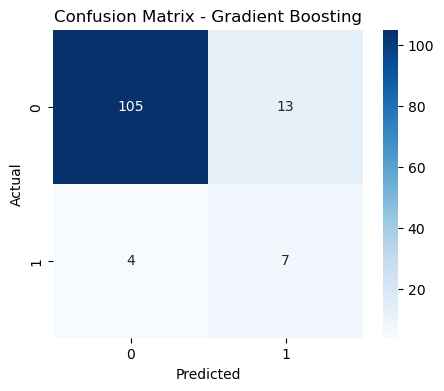

MODEL: CatBoost
Accuracy : 0.8372
Precision: 0.2917
Recall   : 0.6364
F1 Score : 0.4000

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.86      0.91       118
           1       0.29      0.64      0.40        11

    accuracy                           0.84       129
   macro avg       0.63      0.75      0.65       129
weighted avg       0.90      0.84      0.86       129



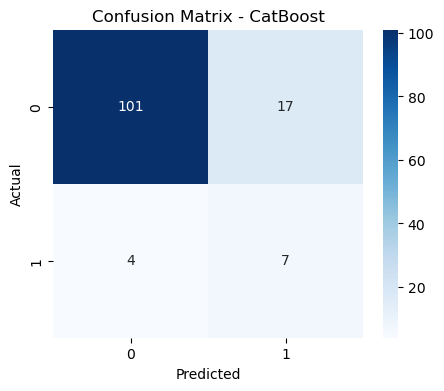

MODEL: Random Forest
Accuracy : 0.7364
Precision: 0.2195
Recall   : 0.8182
F1 Score : 0.3462

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.73      0.83       118
           1       0.22      0.82      0.35        11

    accuracy                           0.74       129
   macro avg       0.60      0.77      0.59       129
weighted avg       0.91      0.74      0.79       129



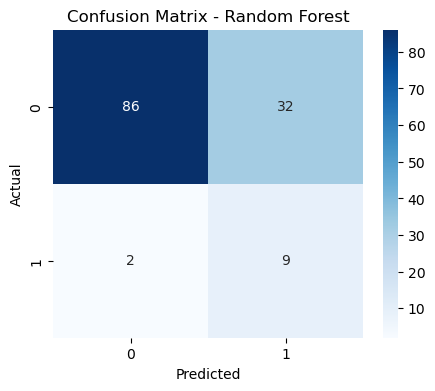

MODEL: XGBoost
Accuracy : 0.8372
Precision: 0.3077
Recall   : 0.7273
F1 Score : 0.4324

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.85      0.90       118
           1       0.31      0.73      0.43        11

    accuracy                           0.84       129
   macro avg       0.64      0.79      0.67       129
weighted avg       0.91      0.84      0.86       129



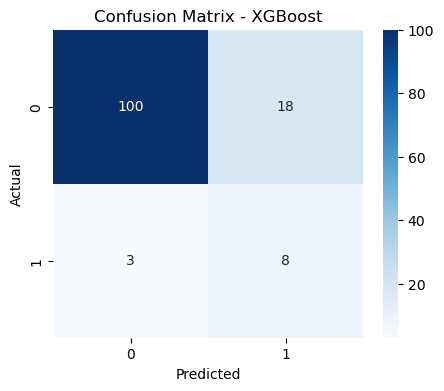


FINAL MODEL COMPARISON:
               Model  Accuracy  Precision    Recall  F1 Score
2      Random Forest  0.736434   0.219512  0.818182  0.346154
3            XGBoost  0.837209   0.307692  0.727273  0.432432
0  Gradient Boosting  0.868217   0.350000  0.636364  0.451613
1           CatBoost  0.837209   0.291667  0.636364  0.400000


In [ ]:
# STORE BEST MODELS
best_models = {
    "Gradient Boosting": best_gb,
    "CatBoost": best_cat,
    "Random Forest": best_rf,
    "XGBoost": best_xgb
}

# SET THRESHOLD
threshold = 0.2

# EVALUATION LOOP
results = []

for name, model in best_models.items():
    X_test_used = X_test

    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test_used)[:, 1]
        y_pred = (y_prob > threshold).astype(int)
    else:
        y_pred = model.predict(X_test_used)
        y_prob = np.zeros(len(y_test))

    acc = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    roc_auc = roc_auc_score(y_test, y_prob) if hasattr(model, "predict_proba") else np.nan
    pr_auc = average_precision_score(y_test, y_prob) if hasattr(model, "predict_proba") else np.nan

    results.append({
        "Model": name,
        "Accuracy": acc,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC AUC": roc_auc,
        "PR AUC": pr_auc
    })

    print("=" * 50)
    print(f"MODEL: {name}")
    print("=" * 50)

    print(f"Accuracy : {acc:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall   : {recall:.4f}")
    print(f"F1 Score : {f1:.4f}")
    print(f"ROC AUC  : {roc_auc:.4f}")

    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, zero_division=0))

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

# RESULTS DATAFRAME
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(by=["F1 Score", "Recall", "ROC AUC"], ascending=[False, False, False])

selected_model_name = results_df.iloc[0]["Model"]
final_model = best_models[selected_model_name]

print("\nFINAL MODEL COMPARISON:")
print(results_df)
print(f"\nSelected model: {selected_model_name}")

In [31]:
print(results_df.columns)

Index(['Model', 'Accuracy', 'Precision', 'Recall', 'F1 Score'], dtype='object')


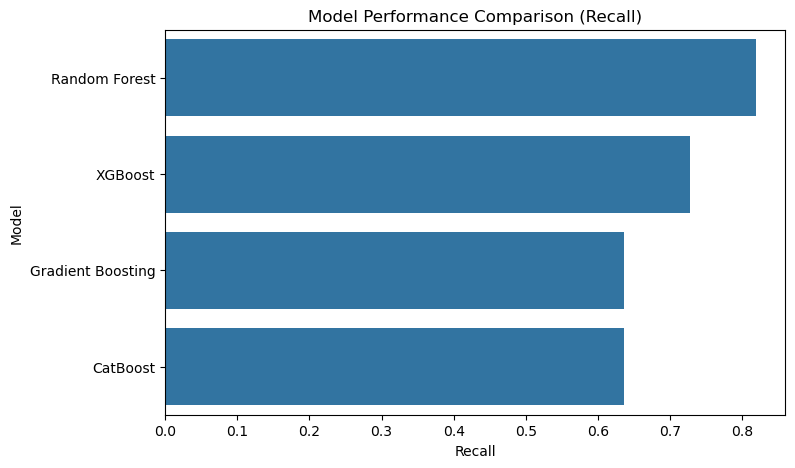

In [32]:
plt.figure(figsize=(8,5))

sns.barplot(data=results_df, x="Recall", y="Model")

plt.title("Model Performance Comparison (Recall)")
plt.xlabel("Recall")
plt.ylabel("Model")

plt.show()

ROC AUC Score: 0.7942989214175655


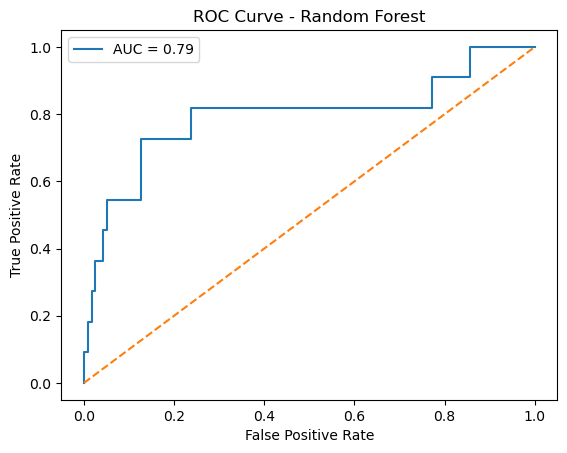

In [33]:
y_prob = best_rf.predict_proba(X_test)[:,1]

auc_score = roc_auc_score(y_test, y_prob)

print("ROC AUC Score:", auc_score)

fpr, tpr, _ = roc_curve(y_test, y_prob)

plt.plot(fpr, tpr, label=f"AUC = {auc_score:.2f}")
plt.plot([0,1],[0,1],'--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Random Forest")

plt.legend()
plt.show()

## 8. Model Selection

In [ ]:
# Use the same model selected by the evaluation loop
best_model = final_model
best_model.fit(X_train_smote, y_train_smote)

print(f"Selected final model: {selected_model_name}")

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              gamma=None, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=None,
              num_parallel_tree=None, random_state=None, ...)

### Insight:
The final model is selected from the tuned-model comparison using the highest combined ranking of F1-score, recall, and ROC-AUC. This makes the notebook selection consistent with the evaluation loop above.


## 9. SHAP analysis

SHAP shape: (129, 27)
X_test shape: (129, 27)


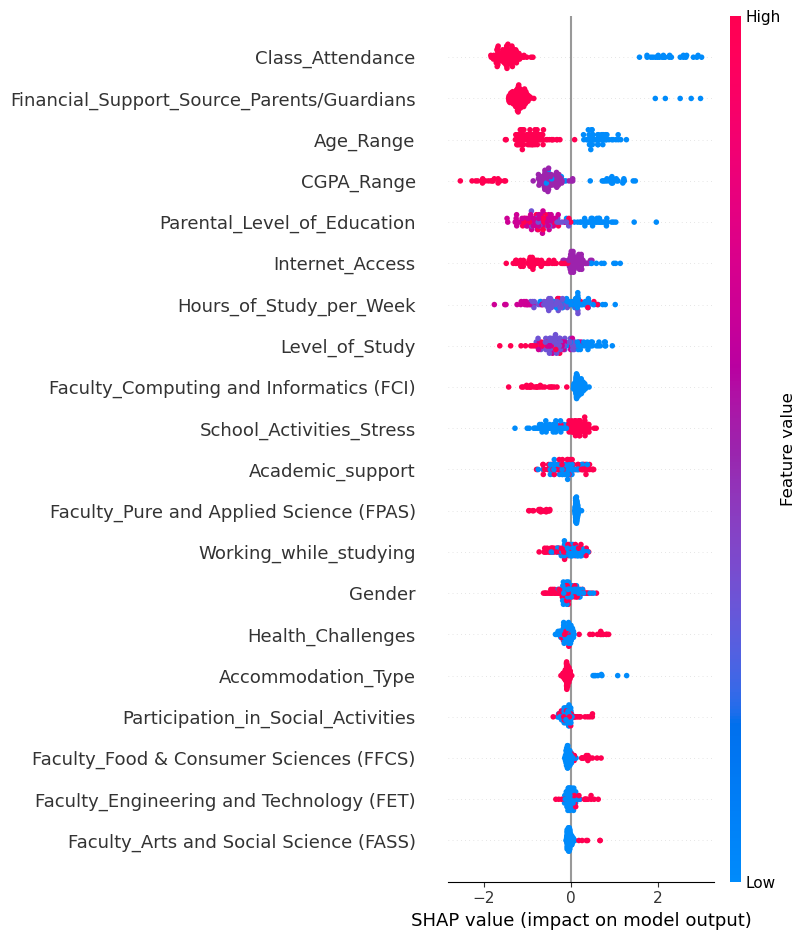

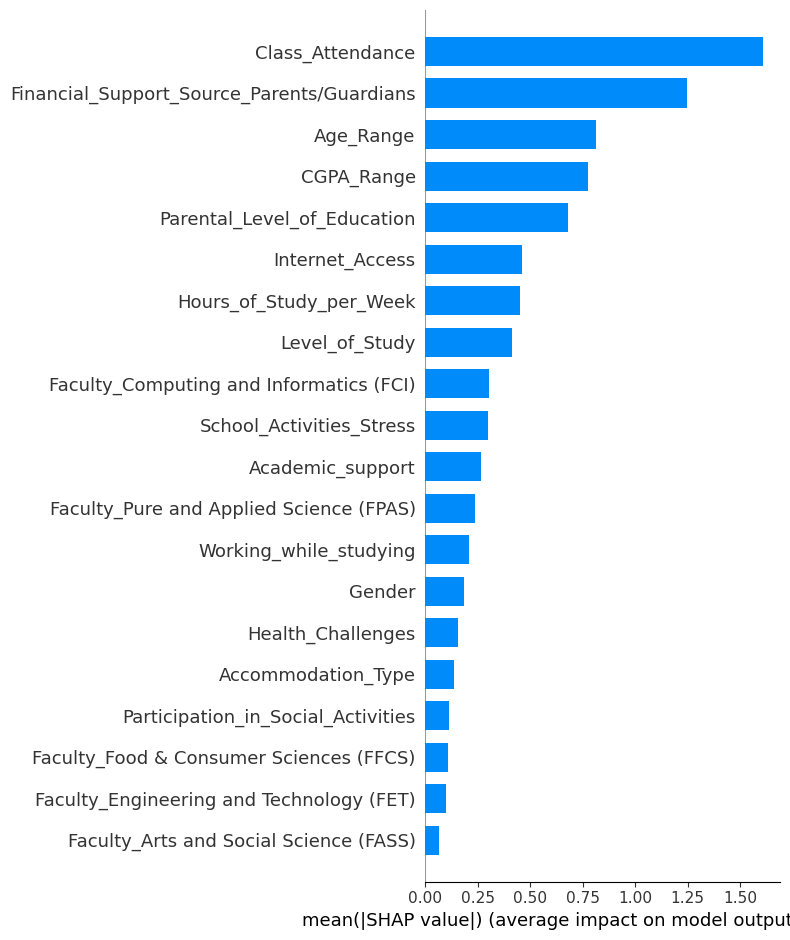

In [ ]:
# Use the selected final model for SHAP analysis
X_test_shap = pd.DataFrame(X_test, columns=X_test.columns).copy()

best_model = final_model

# SHAP Explainer
explainer = shap.TreeExplainer(best_model)

# Calculate SHAP values
shap_values = explainer.shap_values(X_test_shap)

# Use the positive class (Dropout_Risk = 1) for binary classification.
if isinstance(shap_values, list):
    shap_to_plot = shap_values[1]
    expected_value = explainer.expected_value[1]
elif np.asarray(shap_values).ndim == 3:
    shap_to_plot = shap_values[:, :, 1]
    expected_value = explainer.expected_value[1]
else:
    shap_to_plot = shap_values
    expected_value = explainer.expected_value

print("SHAP shape:", np.array(shap_to_plot).shape)
print("X_test shape:", X_test_shap.shape)

# Summary plot
shap.summary_plot(shap_to_plot, X_test_shap)

# Bar plot
shap.summary_plot(shap_to_plot, X_test_shap, plot_type="bar")

shap.initjs()

index = 0

shap.force_plot(
    expected_value,
    shap_to_plot[index],
    X_test_shap.iloc[index],
    feature_names=X_test_shap.columns
)

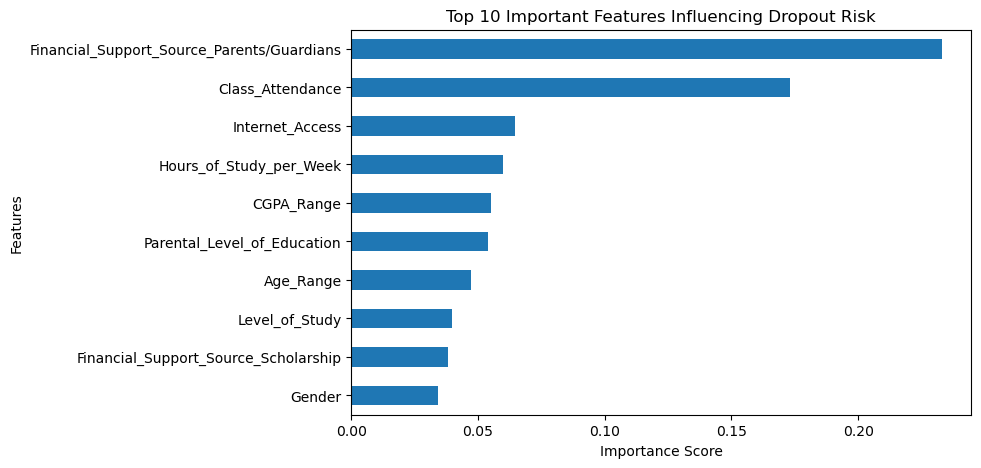

In [36]:
feature_importance = pd.Series(
    best_rf.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

top10 = feature_importance.head(10)

plt.figure(figsize=(8,5))
top10.plot(kind='barh')

plt.title("Top 10 Important Features Influencing Dropout Risk")
plt.xlabel("Importance Score")
plt.ylabel("Features")

plt.gca().invert_yaxis()

plt.show()

## 9. Model Saving (Pickle)

In [ ]:
# Select the best model chosen by the evaluation ranking
best_model = final_model

# Absolute path (base directory)
BASE_DIR = Path.cwd().parent

# Save model
artifacts_path = BASE_DIR / "artifacts"
artifacts_path.mkdir(exist_ok=True)

# Save model using joblib (better for sklearn objects)
joblib.dump(best_model, artifacts_path / "model.pkl")

# Save scaler using joblib (StandardScaler used for feature scaling)
joblib.dump(scaler, artifacts_path / "scaler.pkl")

# Save threshold (0.2 used in evaluation)
np.save(artifacts_path / "threshold.npy", 0.2)

print("Model, scaler, and threshold saved successfully with Joblib!")
print(f"   - Model: {artifacts_path / 'model.pkl'}")
print(f"   - Scaler: {artifacts_path / 'scaler.pkl'}")
print(f"   - Threshold: {artifacts_path / 'threshold.npy'}")

 Model, scaler, and threshold saved successfully with Joblib!
   - Model: c:\Final Year ML Project\artifacts\model.pkl
   - Scaler: c:\Final Year ML Project\artifacts\scaler.pkl
   - Threshold: c:\Final Year ML Project\artifacts\threshold.npy
